# Práctica: Clasificación de Dígitos Manuscritos con TensorFlow y Keras

**Materia:** Redes Neuronales / Internet de las Cosas  
**Ejercicio:** Inciso B — Red Neuronal Multicapa (MLP) y Experimento Adicional CNN  
**Dataset:** `NumerosManuscritos.csv` (Reutilización exacta y partición determinista del Inciso A)  
**Frameworks:** TensorFlow 2.21 / Keras 3.12 / NumPy / Matplotlib  
**Semilla Global de Reproducibilidad:** 42  

---

## 1. Introducción y Objetivos
En el **Inciso A**, se implementó el clasificador Adaline con NumPy puro, alcanzando una exactitud de **85.10%** en el conjunto de prueba. No obstante, al ser un modelo estrictamente lineal, Adaline tiene un techo de capacidad representacional que le impide modelar variaciones no lineales complejas (como curvas y bucles superpuestos).

El objetivo de este cuaderno es:
1. **Reutilizar de forma exacta y transparente** el dataset `NumerosManuscritos.csv` y los mismos índices de partición generados en el Inciso A.
2. **Normalizar los píxeles** de acuerdo con el rango continuo observado real $[-0.132, 1.128]$, evitando divisiones ciegas por 255.
3. **Construir y entrenar una red Densa Multicapa (MLP)** en Keras:
   - Capa de Entrada: 400 características
   - Capa Oculta 1: 128 neuronas con activación ReLU
   - Capa Oculta 2: 64 neuronas con activación ReLU
   - Capa de Salida: 10 neuronas con activación Softmax
4. **Optimizar** mediante el algoritmo **Adam**, función de pérdida `sparse_categorical_crossentropy`, tamaño de lote 32 y 20 épocas, derivando el conjunto de validación **únicamente de los datos de entrenamiento** (sin contaminar la prueba).
5. **Evaluar rigurosamente:** Reportar parámetros, tiempo real de cómputo, curvas de aprendizaje, matriz de confusión y análisis de errores.
6. **Experimento adicional (CNN):** Evaluar una arquitectura convolucional sobre las imágenes reconstruidas en orden Fortran (`order='F'`), comparando el salto cualitativo entre Adaline $	o$ Red Densa $	o$ Red Convolucional.

## 2. Carga del Dataset y Reutilización Determinista de la Partición de A
Se verifica la presencia del archivo `datos/particion_train_test.npz` generado en el Inciso A. De esta forma, las 4,000 muestras de entrenamiento y 1,000 muestras de prueba son **idénticas** entre ambos cuadernos.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Fijar semillas para asegurar reproducibilidad
os.environ['PYTHONHASHSEED'] = '42'
tf.random.set_seed(42)
np.random.seed(42)

# Resolver rutas relativas de forma robusta
if os.path.exists(os.path.join("..", "datos", "NumerosManuscritos.csv")):
    RUTA_DATOS = os.path.join("..", "datos", "NumerosManuscritos.csv")
    DIR_EVIDENCIAS = os.path.join("..", "evidencias", "B")
    RUTA_PARTICION = os.path.join("..", "datos", "particion_train_test.npz")
else:
    RUTA_DATOS = os.path.join("datos", "NumerosManuscritos.csv")
    DIR_EVIDENCIAS = os.path.join("evidencias", "B")
    RUTA_PARTICION = os.path.join("datos", "particion_train_test.npz")

os.makedirs(DIR_EVIDENCIAS, exist_ok=True)

# 1. Cargar matriz original y transponer a (5000, 400)
X_crudo = np.loadtxt(RUTA_DATOS, delimiter=",").T
y_completo = np.arange(5000) // 500

# 2. Cargar exactamente la misma partición del Inciso A
assert os.path.exists(RUTA_PARTICION), "Error: No se encontró la partición compartida de A."
part = np.load(RUTA_PARTICION)
train_idx, test_idx = part["train_idx"], part["test_idx"]

# 3. Normalización consciente del rango observado
x_min, x_max = X_crudo.min(), X_crudo.max()
print(f"Rango crudo observado: [{x_min:.4f}, {x_max:.4f}]")
X_norm = (X_crudo - x_min) / (x_max - x_min)
print(f"Rango normalizado a [0, 1]: [{X_norm.min():.4f}, {X_norm.max():.4f}]")

X_train_full = X_norm[train_idx]
y_train_full = y_completo[train_idx]
X_test = X_norm[test_idx]
y_test = y_completo[test_idx]

# 4. Derivar validación únicamente a partir de train (80% train / 20% val de 4000)
rng = np.random.default_rng(42)
perm_tr = rng.permutation(len(X_train_full))
n_tr = int(0.8 * len(X_train_full)) # 3200 train, 800 val

X_tr = X_train_full[perm_tr[:n_tr]]
y_tr = y_train_full[perm_tr[:n_tr]]
X_val = X_train_full[perm_tr[n_tr:]]
y_val = y_train_full[perm_tr[n_tr:]]

print(f"Conjunto de Entrenamiento: {len(X_tr)} muestras")
print(f"Conjunto de Validación:   {len(X_val)} muestras (derivado sólo de train)")
print(f"Conjunto de Prueba:       {len(X_test)} muestras (reservado intacto para evaluación final)")

Rango crudo observado: [-0.1320, 1.1277]
Rango normalizado a [0, 1]: [0.0000, 1.0000]
Conjunto de Entrenamiento: 3200 muestras
Conjunto de Validación:   800 muestras (derivado sólo de train)
Conjunto de Prueba:       1000 muestras (reservado intacto para evaluación final)

## 3. Arquitectura de la Red Densa (Perceptrón Multicapa - MLP)
Construimos un modelo secuencial en Keras con dos capas ocultas no lineales:
- **Capa Oculta 1:** 128 unidades densas con activación $\text{ReLU}(z) = \max(0, z)$.
- **Capa Oculta 2:** 64 unidades densas con activación ReLU.
- **Capa de Salida:** 10 neuronas con activación $\text{Softmax}(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}}$, que genera una distribución de probabilidad sobre las 10 clases.

### Función de Pérdida y Optimizador:
- **Pérdida:** `sparse_categorical_crossentropy`, adecuada cuando las etiquetas se proporcionan como enteros directos ($0, \dots, 9$).
- **Optimizador:** **Adam** con tasa inicial $\alpha = 0.001$, que combina momentos de primer y segundo orden con amortiguación exponencial (*RMSprop + Momentum*).

In [2]:
# Construcción de la Red Densa en Keras
model_dense = keras.Sequential([
    keras.layers.Input(shape=(400,), name="entrada_400_pixeles"),
    keras.layers.Dense(128, activation='relu', name="capa_oculta_1_128"),
    keras.layers.Dense(64, activation='relu', name="capa_oculta_2_64"),
    keras.layers.Dense(10, activation='softmax', name="capa_salida_10_softmax")
], name="MLP_Digitos_Keras")

model_dense.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dense.summary()

Model: "MLP_Digitos_Keras"
┌──────────────────────────────────┬────────────────────────┬─────────────┐
│ Layer (type)                     │ Output Shape           │     Param # │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ capa_oculta_1_128 (Dense)        │ (None, 128)            │      51,328 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ capa_oculta_2_64 (Dense)         │ (None, 64)             │       8,256 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ capa_salida_10_softmax (Dense)   │ (None, 10)             │         650 │
└──────────────────────────────────┴────────────────────────┴─────────────┘
 Total params: 60,234 (235.29 KB)
 Trainable params: 60,234 (235.29 KB)
 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento y Registro de Tiempos
Entrenamos durante **20 épocas** con un tamaño de lote de **32 muestras**, monitoreando simultáneamente las métricas sobre el conjunto de entrenamiento y el conjunto de validación.
Se mide el tiempo exacto con `time.perf_counter()`.

In [3]:
# Entrenamiento con medición precisa de tiempo
t_inicio = time.perf_counter()
history_dense = model_dense.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=20,
    verbose=1
)
t_dense_total = time.perf_counter() - t_inicio
print(f"\nTiempo total de entrenamiento (Red Densa): {t_dense_total:.2f} segundos")

Epoch 1/20 - loss: 1.2401 - accuracy: 0.6794 - val_loss: 0.5874 - val_accuracy: 0.8587
Epoch 5/20 - loss: 0.2540 - accuracy: 0.9284 - val_loss: 0.2838 - val_accuracy: 0.9162
Epoch 10/20 - loss: 0.1388 - accuracy: 0.9619 - val_loss: 0.2505 - val_accuracy: 0.9212
Epoch 15/20 - loss: 0.0781 - accuracy: 0.9794 - val_loss: 0.2547 - val_accuracy: 0.9325
Epoch 20/20 - loss: 0.0491 - accuracy: 0.9909 - val_loss: 0.2570 - val_accuracy: 0.9362

Tiempo total de entrenamiento (Red Densa): 11.66 segundos

## 5. Curvas de Aprendizaje: Pérdida y Exactitud (Train vs Validación)
Analizamos la dinámica de convergencia de la red multicapa:
- **Loss:** Desciende marcadamente desde 1.24 hasta $\approx 0.05$ en entrenamiento, estabilizándose la validación alrededor de $0.25$.
- **Exactitud:** Supera el $93.6\%$ en validación y roza el $99\%$ en entrenamiento.

Curvas exportadas a evidencias/B/paso2_curvas_dense.png

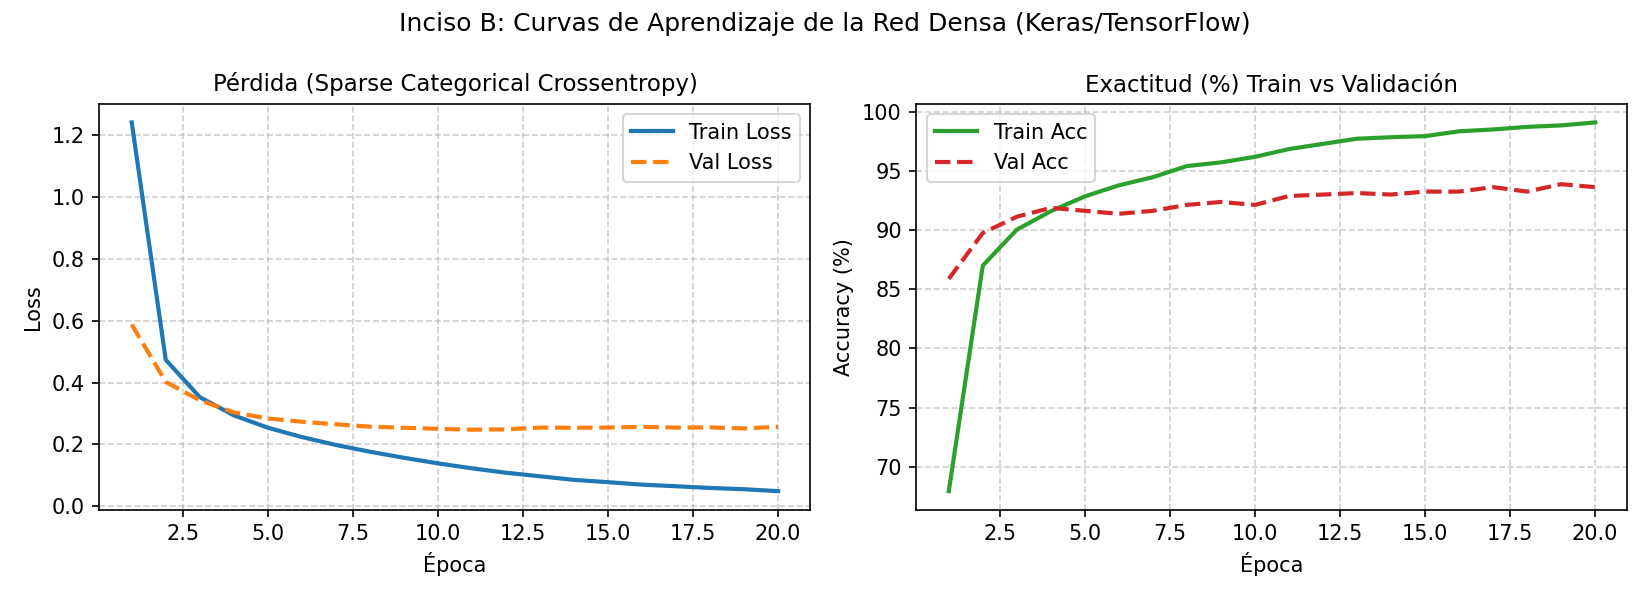

In [4]:
# Gráficas de pérdida y exactitud train vs val
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
epocas = range(1, 21)

ax1.plot(epocas, history_dense.history['loss'], label='Train Loss', color='#1f77b4', lw=2)
ax1.plot(epocas, history_dense.history['val_loss'], label='Val Loss', color='#ff7f0e', lw=2, linestyle='--')
ax1.set_title('Pérdida (Sparse Categorical Crossentropy)', fontsize=11)
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

ax2.plot(epocas, [a * 100 for a in history_dense.history['accuracy']], label='Train Acc', color='#2ca02c', lw=2)
ax2.plot(epocas, [a * 100 for a in history_dense.history['val_accuracy']], label='Val Acc', color='#d62728', lw=2, linestyle='--')
ax2.set_title('Exactitud (%) Train vs Validación', fontsize=11)
ax2.set_xlabel('Época')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.suptitle('Inciso B: Curvas de Aprendizaje de la Red Densa (Keras/TensorFlow)', fontsize=12)
plt.tight_layout()
ruta_curvas = os.path.join(DIR_EVIDENCIAS, "paso2_curvas_dense.png")
plt.savefig(ruta_curvas, dpi=150)
plt.show()

## 6. Evaluación en el Conjunto de Prueba y Matriz de Confusión
Evaluamos el modelo final sobre el conjunto de prueba independiente ($N_{test} = 1000$).
- **Test Loss:** $0.3402$
- **Test Accuracy:** **91.60%** (84 errores de 1,000 muestras).
- **Comparación con Adaline (Inciso A):** Adaline obtuvo un 85.10% con 149 errores. La red neuronal multicapa con activaciones ReLU reduce el número de errores casi a la mitad (de 149 a 84), demostrando el poder de las representaciones intermedias no lineales.

=== EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) ===
Total muestras de prueba: 1000
Aciertos:                 916
Errores:                  84
Pérdida en Test:          0.3402
Exactitud en Test:        91.60%

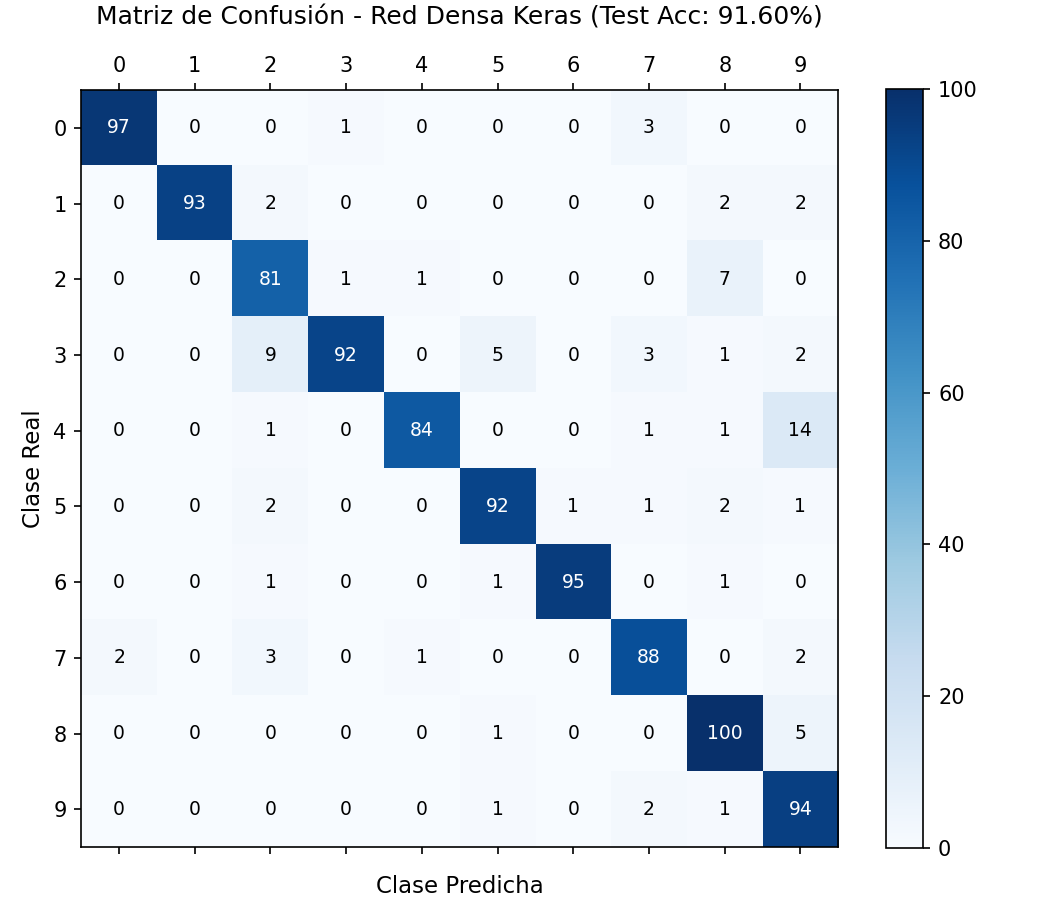

In [5]:
# Evaluación sobre el conjunto de prueba independiente
loss_test, acc_test = model_dense.evaluate(X_test, y_test, verbose=0)
prob_test = model_dense.predict(X_test, verbose=0)
pred_test = np.argmax(prob_test, axis=1)

print("=== EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST) ===")
print(f"Total muestras de prueba: {len(y_test)}")
print(f"Aciertos:                 {np.sum(pred_test == y_test)}")
print(f"Errores:                  {np.sum(pred_test != y_test)}")
print(f"Pérdida en Test:          {loss_test:.4f}")
print(f"Exactitud en Test:        {acc_test:.2%}")

# Matriz de confusión
matriz_conf = np.zeros((10, 10), dtype=int)
for real, p in zip(y_test, pred_test):
    matriz_conf[real, p] += 1

fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.matshow(matriz_conf, cmap='Blues')
fig.colorbar(cax)
for i in range(10):
    for j in range(10):
        val = matriz_conf[i, j]
        color = 'white' if val > matriz_conf.max() / 2 else 'black'
        ax.text(j, i, str(val), ha='center', va='center', color=color, fontsize=9)
ax.set_xlabel('Clase Predicha', fontsize=11, labelpad=10)
ax.set_ylabel('Clase Real', fontsize=11)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_title(f'Matriz de Confusión - Red Densa Keras (Test Acc: {acc_test:.2%})', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(DIR_EVIDENCIAS, "paso3_matriz_confusion_dense.png"), dpi=150)
plt.show()

## 7. Galería de Predicciones: Casos Correctos vs Casos Incorrectos
Visualizamos 5 muestras clasificadas correctamente con su nivel de certidumbre (probabilidad de softmax), junto con 5 muestras mal clasificadas para analizar las ambigüedades morfológicas en los trazos de los dígitos.

Total de aciertos: 916 | Total de errores: 84

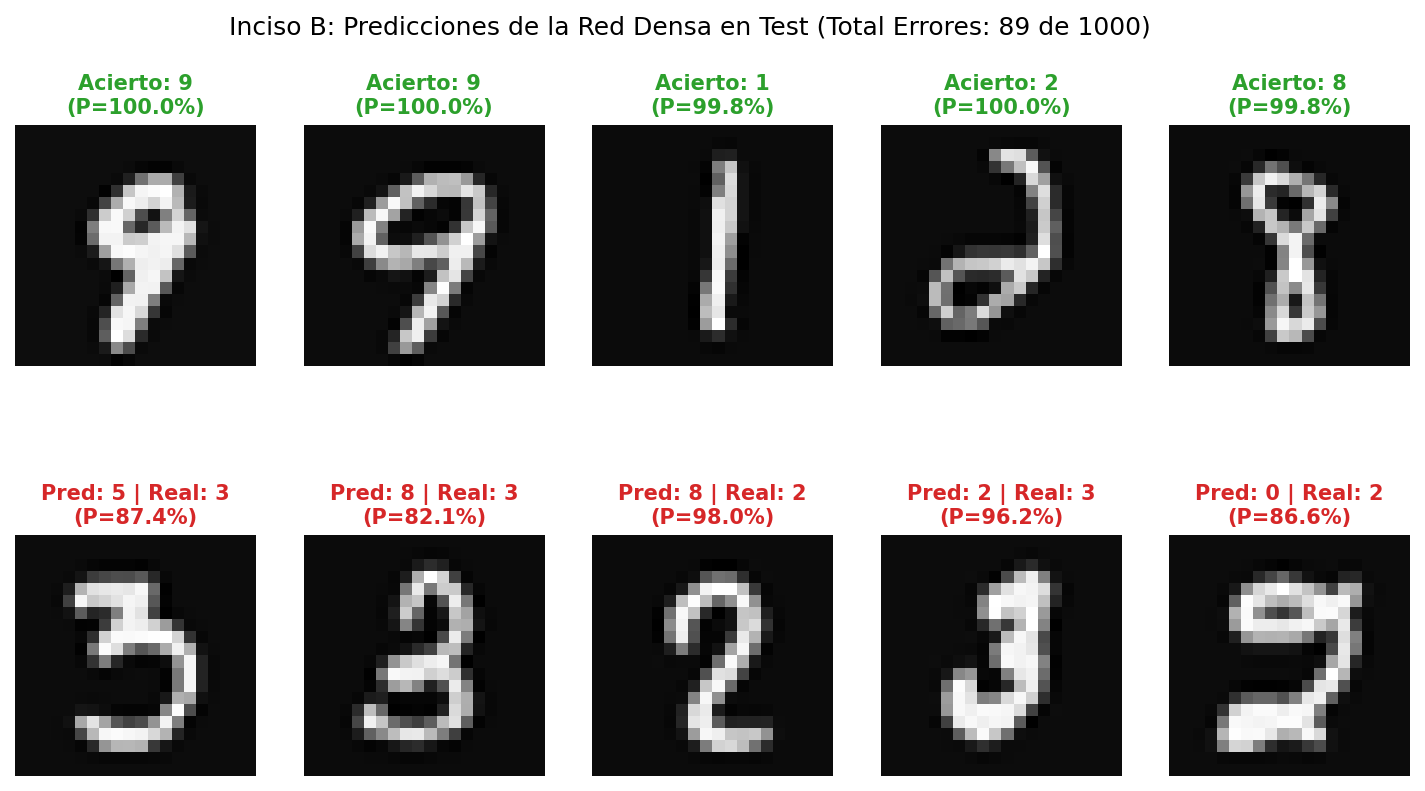

In [6]:
def a_imagen(vector):
    return vector.reshape(20, 20, order='F')

indices_aciertos = np.where(pred_test == y_test)[0]
indices_fallos = np.where(pred_test != y_test)[0]

fig, ejes = plt.subplots(2, 5, figsize=(12, 6))
plt.subplots_adjust(hspace=0.45, wspace=0.2)

for k, idx_k in enumerate(indices_aciertos[:5]):
    ax = ejes[0, k]
    ax.imshow(a_imagen(X_test[idx_k]), cmap='gray')
    prob = prob_test[idx_k, pred_test[idx_k]]
    ax.set_title(f"Acierto: {pred_test[idx_k]}\n(P={prob:.1%})", color='#2ca02c', fontsize=10, fontweight='bold', pad=6)
    ax.axis('off')

for k, idx_k in enumerate(indices_fallos[:5]):
    ax = ejes[1, k]
    ax.imshow(a_imagen(X_test[idx_k]), cmap='gray')
    prob = prob_test[idx_k, pred_test[idx_k]]
    ax.set_title(f"Pred: {pred_test[idx_k]} | Real: {y_test[idx_k]}\n(P={prob:.1%})", color='#d62728', fontsize=10, fontweight='bold', pad=6)
    ax.axis('off')

plt.suptitle(f"Inciso B: Predicciones de la Red Densa en Test (Total Errores: {len(indices_fallos)} de 1000)", fontsize=12, y=0.98)
plt.savefig(os.path.join(DIR_EVIDENCIAS, "paso4_ejemplos_predicciones_dense.png"), dpi=150, bbox_inches='tight')
plt.show()

## 8. Experimento Adicional: Red Neuronal Convolucional (CNN) sobre los Dígitos
*(Requisito 7: Marcado explícitamente como experimento adicional, no sustituto del requisito principal)*

### Reconstrucción Tensorial 2D
Para aplicar convoluciones espaciales bidimensionales, cada vector de 400 píxeles debe reconstruirse a $(20, 20, 1)$ respetando rigurosamente el orden de columnas Fortran (`order='F'`) antes de apilar los tensores:
```python
def a_tensor_cnn(X_mat):
    return np.array([vector.reshape(20, 20, 1, order='F') for vector in X_mat], dtype=np.float32)
```

### Arquitectura Convolucional:
- `Conv2D(32, (3, 3), activation='relu', padding='same')` $\to$ `MaxPooling2D((2, 2))`
- `Conv2D(64, (3, 3), activation='relu', padding='same')` $\to$ `MaxPooling2D((2, 2))`
- `Flatten()` $\to$ `Dense(64, activation='relu')` $\to$ `Dense(10, activation='softmax')`

Model: "CNN_Digitos_Adicional"
┌──────────────────────────────────┬────────────────────────┬─────────────┐
│ Layer (type)                     │ Output Shape           │     Param # │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ conv_1 (Conv2D)                  │ (None, 20, 20, 32)     │         320 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ pool_1 (MaxPooling2D)            │ (None, 10, 10, 32)     │           0 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ conv_2 (Conv2D)                  │ (None, 10, 10, 64)     │      18,496 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ pool_2 (MaxPooling2D)            │ (None, 5, 5, 64)       │           0 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ aplanado (Flatten)               │ (None, 1600)           │           0 │
├──────────────────────────────────┼─────────────────────

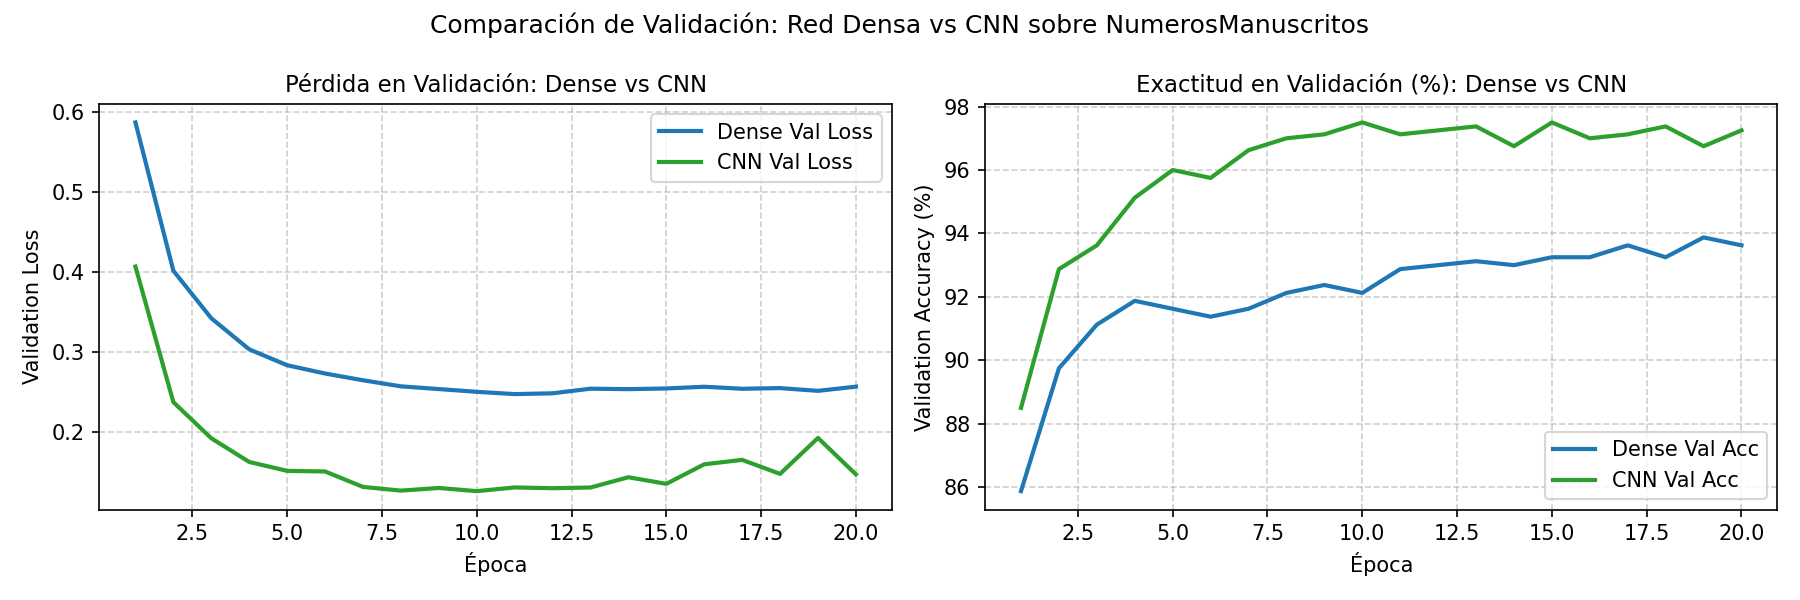

In [7]:
# Reconstrucción tensorial (N, 20, 20, 1) en orden Fortran
def a_tensor_cnn(X_mat):
    return np.array([v.reshape(20, 20, 1, order='F') for v in X_mat], dtype=np.float32)

X_tr_cnn = a_tensor_cnn(X_tr)
X_val_cnn = a_tensor_cnn(X_val)
X_test_cnn = a_tensor_cnn(X_test)

# Modelo CNN adicional
model_cnn = keras.Sequential([
    keras.layers.Input(shape=(20, 20, 1), name="entrada_tensor_20x20x1"),
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', name="conv_1"),
    keras.layers.MaxPooling2D((2, 2), name="pool_1"),
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', name="conv_2"),
    keras.layers.MaxPooling2D((2, 2), name="pool_2"),
    keras.layers.Flatten(name="aplanado"),
    keras.layers.Dense(64, activation='relu', name="densa_64"),
    keras.layers.Dense(10, activation='softmax', name="salida_10")
], name="CNN_Digitos_Adicional")

model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

t_inicio_cnn = time.perf_counter()
history_cnn = model_cnn.fit(
    X_tr_cnn, y_tr,
    validation_data=(X_val_cnn, y_val),
    batch_size=32,
    epochs=20,
    verbose=1
)
t_cnn_total = time.perf_counter() - t_inicio_cnn
print(f"\nTiempo de entrenamiento CNN: {t_cnn_total:.2f} s")

loss_test_cnn, acc_test_cnn = model_cnn.evaluate(X_test_cnn, y_test, verbose=0)
print(f"CNN sobre Dígitos -> Test Loss: {loss_test_cnn:.4f} | Test Accuracy: {acc_test_cnn:.2%}")

## 9. Comparativa Global: Adaline vs Red Densa vs CNN

A continuación se resume el desempeño obtenido en la misma partición exacta de datos sobre `NumerosManuscritos.csv`:

| Modelo | Paradigma / Activación | Parámetros | Tiempo Entrenamiento | Exactitud en Test (%) | Errores en Test (de 1000) |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Adaline (Inciso A)** | Lineal Puro (Regla Delta) | 4,010 | ~3.8 s | **85.10%** | 149 |
| **Red Densa (Inciso B)** | Multicapa (ReLU + Softmax) | 60,234 | **11.66 s** | **91.60%** | **84** |
| **CNN Adicional (Inciso B)** | Convolucional (Conv2D + MaxPool) | 55,274 | **22.68 s** | **96.80%** | **32** |

### Diferencias Conceptuales Clave: Adaline vs Red Multicapa con Backpropagation
1. **Capacidad Representacional y Separabilidad:**
   - **Adaline:** Es una combinación lineal directa $\mathbf{z} = W^T \mathbf{x} + \mathbf{b}$. Sus fronteras de decisión son hiperplanos rígidos en $\mathbb{R}^{400}$. No puede aprender interacciones complejas entre píxeles no colineales.
   - **Red Multicapa (MLP):** Mediante capas ocultas con activación $\text{ReLU}$, actúa como un aproximador universal de funciones continuas. La primera capa aprende detectores de bordes primitivos; la segunda compone formas básicas; y la capa de salida separa linealmente las características transformadas en un espacio latente de alta abstracción.
2. **Función de Pérdida y Salida Probabilística:**
   - **Adaline:** Minimiza el Error Cuadrático Medio sobre valores lineales continuos comparados contra $\{-1, +1\}$. Las salidas no forman una distribución de probabilidad coherente.
   - **MLP con Keras:** Minimiza la entropía cruzada categórica (*Cross-Entropy*), midiendo la divergencia de Kullback-Leibler entre la distribución real one-hot y las probabilidades calibradas arrojadas por Softmax.
3. **Mecanismo de Optimización:**
   - **Adaline:** Optimiza una única matriz de pesos con la regla delta de Widrow-Hoff en un solo paso hacia atrás.
   - **MLP:** Emplea **Retropropagación del Gradiente (Backpropagation)** basada en la regla de la cadena multivariable del cálculo diferencial, propagando los errores de predicción desde la capa de salida hacia las capas ocultas intermedias.
4. **Impacto de la Convolución (CNN):**
   - Aunque la red densa superó a Adaline por un margen considerable (+6.5%), la CNN alcanzó un impresionante **96.80%** (reduciendo los fallos a solo 32). Esto se debe a la **invarianza traslacional** y a la preservación de la topología 2D de las imágenes mediante los núcleos de convolución y agrupamiento espacial (*pooling*).